# Scalpel Vibrations

Can describe the scalpel's motion as simple harmonic motion.

The general equation for simple harmonic motion is:

$$
x(t) = A\cos(\omega t)
$$
For an example excursion of 150 µm ($A = 75\ \mu\text{m}$) at $f = 50\ \text{kHz}$ ($\omega = 2\pi f \approx 314{,}200\ \text{rad/s}$):

$$
x(t) = 0.000075\cos(314{,}200\, t)
$$

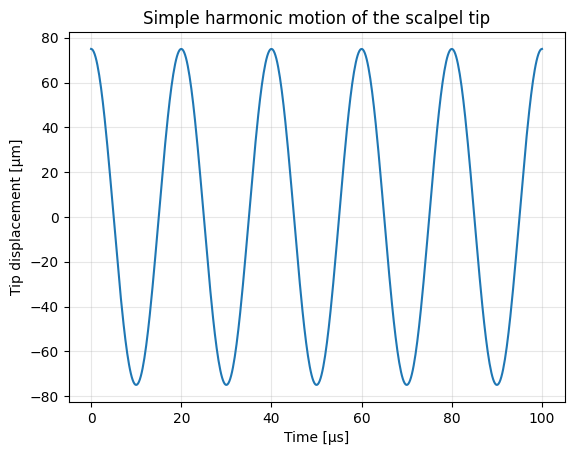

Amplitude: 75.0 µm
Max speed: 23.6 m/s
Max acceleration: 7.40e+06 m/s^2


In [14]:
import numpy as np
import matplotlib.pyplot as plt

excursion = 150e-6    #peak-to-peak tip excursion [m] - needs to be in range 0-600micrometres
A = excursion / 2     #amplitude used in x = A cos(wt) [m]
f = 50e3              #frequency [Hz] - needs to be in range 20-60Hz
w = 2 * np.pi * f     #angular frequency [rad/s]

t = np.linspace(0, 5/f, 500)   #5 cycles
x = A * np.cos(w * t)

plt.plot(t * 1e6, x * 1e6)
plt.xlabel("Time [µs]")
plt.ylabel("Tip displacement [µm]")
plt.title("Simple harmonic motion of the scalpel tip")
plt.grid(alpha=0.3)
plt.show()

print(f"Amplitude: {A*1e6:.1f} µm")
print(f"Max speed: {A*w:.1f} m/s")
print(f"Max acceleration: {A*w**2:.2e} m/s^2")

Looking at how it varies across 0-600micrometres excursion, and 20-60kHz frequency:
Substituting $A = s/2$ and $\omega = 2\pi f$ into the maximum speed and acceleration gives:

$$
v_{max} = A\omega = \pi f s
$$

$$
a_{max} = A\omega^2 = 2\pi^2 f^2 s
$$

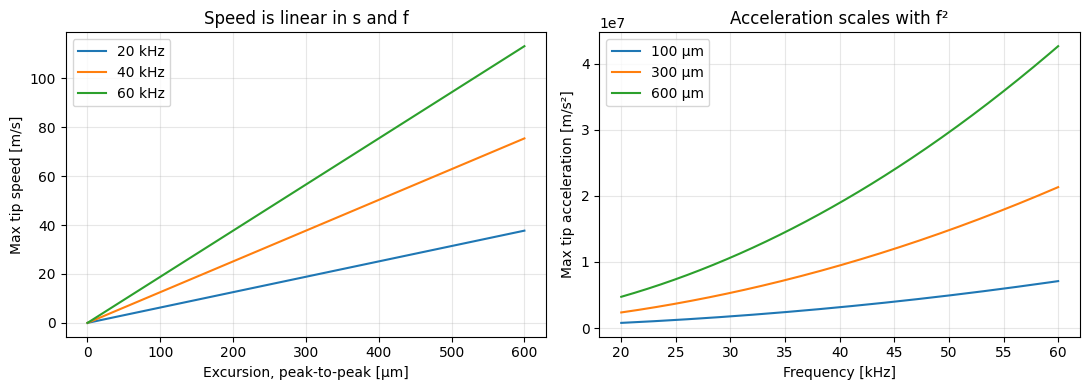

In [15]:
#ranges
s = np.linspace(0, 600e-6, 200)       #excursion, peak-to-peak [m]
f = np.linspace(20e3, 60e3, 200)      #frequency [Hz]

fig, ax = plt.subplots(1, 2, figsize=(11, 4))

#Left: max speed vs excursion, at a few frequencies
for f_i in [20e3, 40e3, 60e3]:
    v_max = np.pi * f_i * s
    ax[0].plot(s * 1e6, v_max, label=f"{f_i/1e3:.0f} kHz")
ax[0].set_xlabel("Excursion, peak-to-peak [µm]")
ax[0].set_ylabel("Max tip speed [m/s]")
ax[0].set_title("Speed is linear in s and f")

#Right: max acceleration vs frequency, at a few excursions
for s_i in [100e-6, 300e-6, 600e-6]:
    a_max = 2 * np.pi**2 * f**2 * s_i
    ax[1].plot(f / 1e3, a_max, label=f"{s_i*1e6:.0f} µm")
ax[1].set_xlabel("Frequency [kHz]")
ax[1].set_ylabel("Max tip acceleration [m/s²]")
ax[1].set_title("Acceleration scales with f²")

for a in ax:
    a.legend()
    a.grid(alpha=0.3)
fig.tight_layout()
plt.show()

Left plot: max tip speed is directly proportional to both excursion and frequency ($v_{max} \propto fs$). <br>
Right plot: max tip acceleration is directly proportional to excursion but proportional to the square of frequency ($a_{max} \propto f^2 s$), so frequency has a much greater effect.

## Damping 

Need to add damping as SHM is unrealistic, and will carry on forever. <br>

The scalpel blade loses some energy every cycle:
- internal friction - in the blade material as it flexes
- losses - in the piezoelectric transducer and its mountings
- acoustic radiation - into the surrounding medium
- **the tissue** - in contact with the tip. LARGEST LOSS

The energy lost to the tissue is turned into heat which causes it to cut and coagulate. Damping is therefore the mechanism that lets the scalpel work, not just a loss to be minimised. The device is driven electrically, but the vibration itself is mechanical.
The generator has to keep supplying power only because damping keeps removing energy.

#### The equation of motion
Damping is modelled as a force proportional to velocity that opposes the motion, $-c\dot{x}$. Adding it to the SHM equation gives:

$$
m\ddot{x} + c\dot{x} + kx = 0
$$

where $m$ is the effective vibrating mass, $c$ is the damping coefficient and $k$ is the stiffness.

Dividing through by $m$ puts the equation in a standard form, and we dont have the mass currently.

$$
\ddot{x} + 2\zeta\omega_0\dot{x} + \omega_0^2 x = 0
$$

| Symbol | Definition | Meaning |
|---|---|---|
| $\omega_0$ | $\sqrt{k/m}$ | natural (resonant) angular frequency |
| $\zeta$ | $\dfrac{c}{2\sqrt{km}}$ | **damping ratio**: $\zeta = 0$ means no damping; ultrasonic blades have $\zeta \ll 1$ |
| $Q$ | $\dfrac{1}{2\zeta}$ | **quality factor**: a high $Q$ means light damping, so the blade "rings" for many cycles |

#### The solution
For light damping ($\zeta \ll 1$), the solution is simple harmonic motion inside a decaying exponential envelope:

$$
x(t) = A\,e^{-\zeta\omega_0 t}\cos(\omega_d t)
$$

where the damped frequency is

$$
\omega_d = \omega_0\sqrt{1-\zeta^2} \approx \omega_0
$$

So the blade still vibrates at almost exactly its natural frequency, but the amplitude shrinks over time.

#### Decay time
The amplitude falls by a factor of $e$ (to about 37%) every time constant:

$$
\tau = \frac{1}{\zeta\omega_0} = \frac{2Q}{\omega_0}
$$

A higher $Q$ (less damping) gives a longer time constant. When the blade touches tissue, damping increases, $Q$ falls and the vibration decays faster. That faster decay is the energy being transferred into the tissue as heat.

Air: zeta = 0.00050, tau = 6.37 ms (~318 cycles)
Tissue: zeta = 0.00167, tau = 1.91 ms (~95 cycles)


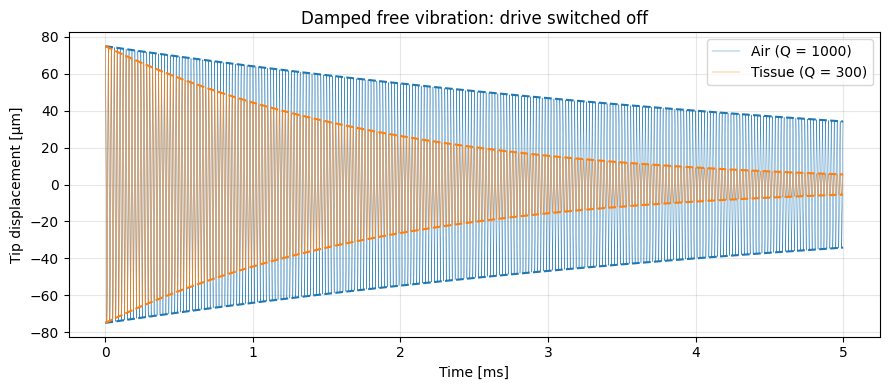

In [16]:
from scipy.integrate import solve_ivp

Q_air = 1000       #FIND ACTUAL VALUES - light damping (blade in air)
Q_tissue = 300     #FIND ACTUAL VALUES - heavier damping (blade on tissue)

#solve.ivp can only handle 1st deriv, so splitting them up
def damped(t, y, zeta):
    x, v = y
    return [v, -2 * zeta * w * v - w**2 * x]
    

f_res = w / (2 * np.pi)                                #scalar frequency, since f is now an array
t_end = 5e-3
t_d = np.linspace(0, t_end, int(t_end * f_res * 40))   #40 points per cycle

#runnning for air, then tissue
fig, ax = plt.subplots(figsize=(9, 4))
for label, Q in [("Air", Q_air), ("Tissue", Q_tissue)]:
    zeta = 1 / (2 * Q)
    sol = solve_ivp(damped, (0, t_end), [A, 0], args=(zeta,), t_eval=t_d,
                    rtol=1e-8, atol=1e-12, max_step=1 / (20 * f_res))
    line, = ax.plot(sol.t * 1e3, sol.y[0] * 1e6, lw=0.3, label=f"{label} (Q = {Q})")

    envelope = A * np.exp(-zeta * w * t_d)             #analytical check
    ax.plot(t_d * 1e3,  envelope * 1e6, "--", color=line.get_color(), lw=1.5)
    ax.plot(t_d * 1e3, -envelope * 1e6, "--", color=line.get_color(), lw=1.5)

    tau = 1 / (zeta * w)
    print(f"{label}: zeta = {zeta:.5f}, tau = {tau*1e3:.2f} ms (~{tau*f_res:.0f} cycles)")

ax.set_xlabel("Time [ms]")
ax.set_ylabel("Tip displacement [µm]")
ax.set_title("Damped free vibration: drive switched off")
ax.legend(loc="upper right")
ax.grid(alpha=0.3)
fig.tight_layout()
plt.show()

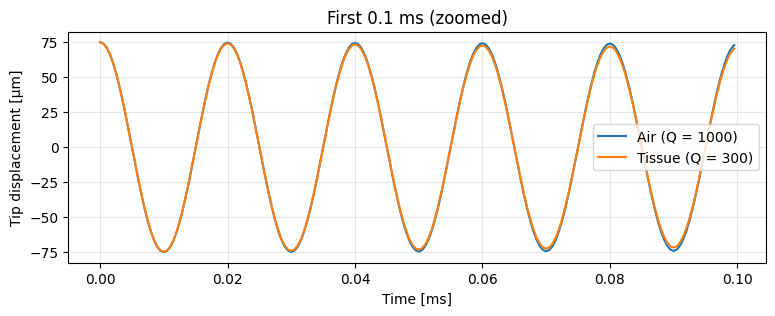

In [17]:
#looking into a smaller time frame, first 0.1 ms - damping only shows up after hundreds of cycles

fig, ax = plt.subplots(figsize=(9, 3))
mask = t_d < 0.1e-3
for label, Q in [("Air", Q_air), ("Tissue", Q_tissue)]:
    zeta = 1 / (2 * Q)
    sol = solve_ivp(damped, (0, 0.1e-3), [A, 0], args=(zeta,), t_eval=t_d[mask],
                    rtol=1e-8, atol=1e-12, max_step=1 / (20 * f_res))
    ax.plot(sol.t * 1e3, sol.y[0] * 1e6, label=f"{label} (Q = {Q})")
ax.set_xlabel("Time [ms]")
ax.set_ylabel("Tip displacement [µm]")
ax.set_title("First 0.1 ms (zoomed)")
ax.legend()
ax.grid(alpha=0.3)
plt.show()

### Driven vibration and resonance

#### Adding a driving force
Without a driving force, damping causes the vibration to decay to zero. In operation, the piezoelectric transducer pushes the blade every cycle, replacing the energy lost to damping. Adding this periodic driving term gives the equation of motion:

$$
\ddot{x} + 2\zeta\omega_0\dot{x} + \omega_0^2 x = a_0\cos(\omega t)
$$

where:

- $a_0 = F_0/m$ is the driving force per unit mass, so the blade's mass is not needed
- $\omega$ is the drive frequency set by the generator, which is not necessarily equal to the blade's natural frequency $\omega_0$

#### Amplitude at resonance
When the drive frequency matches the natural frequency ($\omega = \omega_0$), the steady-state amplitude is:

$$
X = \frac{a_0}{2\zeta\omega_0^2}
$$

The amplitude is inversely proportional to the damping ratio. For the same driving force, a lightly damped blade (in air) vibrates with a much larger amplitude than a heavily damped one (in tissue). This is why the standard warns against operating the device without load.

#### Amplitude away from resonance
For a general drive frequency, the steady-state amplitude is:

$$
X(\omega) = \frac{a_0}{\sqrt{(\omega_0^2 - \omega^2)^2 + (2\zeta\omega_0\omega)^2}}
$$

This gives the resonance curve, a sharp peak at $\omega_0$ that falls away rapidly on either side. Because the peak is so narrow, the drive frequency has to match the resonant frequency closely to achieve the required excursion. This is why most systems use automatic frequency control.

Air: steady-state amplitude = 75.0 µm (excursion 150 µm)
Tissue: steady-state amplitude = 22.5 µm (excursion 45 µm)


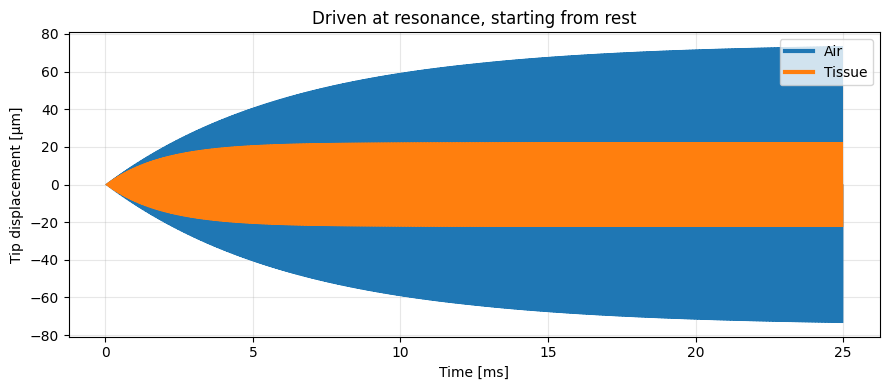

In [19]:
#creating ratios 
zeta_air = 1 / (2 * Q_air)
zeta_tissue = 1 / (2 * Q_tissue)

#Drive strength (force per unit mass, a0 = F0/m)
#Rearranged from X = a0 / (2*zeta*w^2) so the blade reaches the chosen excursion in air at resonance
a0 = A * 2 * zeta_air * w**2

def driven(t, y, zeta, w_drive):
    x, v = y
    return [v, a0 * np.cos(w_drive * t) - 2 * zeta * w * v - w**2 * x]

t_end = 25e-3
t_dr = np.linspace(0, t_end, int(t_end * f_res * 40))

fig, ax = plt.subplots(figsize=(9, 4))
for label, zeta in [("Air", zeta_air), ("Tissue", zeta_tissue)]:
    sol = solve_ivp(driven, (0, t_end), [0, 0], args=(zeta, w), t_eval=t_dr,
                    rtol=1e-8, atol=1e-12, max_step=1 / (20 * f_res))
    ax.plot(sol.t * 1e3, sol.y[0] * 1e6, lw=0.3, label=label)

    X_ss = a0 / (2 * zeta * w**2)
    print(f"{label}: steady-state amplitude = {X_ss*1e6:.1f} µm (excursion {2*X_ss*1e6:.0f} µm)")

ax.set_xlabel("Time [ms]")
ax.set_ylabel("Tip displacement [µm]")
ax.set_title("Driven at resonance, starting from rest")
leg = ax.legend(loc="upper right")
for line in leg.get_lines():
    line.set_linewidth(3) 
ax.grid(alpha=0.3)
fig.tight_layout()
plt.show()

### Response when driven at resonance

The blade starts at rest and is driven at its resonant frequency. Each cycle, the drive adds energy, so the amplitude grows until the energy lost to damping per cycle equals the energy supplied by the drive. At this point the vibration reaches a steady state and the amplitude stops increasing.

- Tissue reaches steady state faster and at a lower amplitude - The higher damping means the energy balance is reached sooner (about 6 ms compared with about 20 ms in air), and more of each push is lost immediately as heat in the tissue.
- The same drive produces very different excursions - With an identical driving force, the excursion is 150 µm in air but only 45 µm in tissue. A real generator therefore cannot apply a fixed force; it has to detect the load and increase its power to maintain the required excursion when the blade contacts tissue.
- Running without load is risky - In air there is little damping to remove energy, so the vibration grows much larger. This is consistent with the standard's warning that operating without load can cause excessive excursion and damage the applicator.

*Note: the Q factors used (1000 in air, 300 in tissue) are assumed values, so the exact amplitudes are illustrative, but the trends above do not depend on them.*

# check below

### Power dissipated into the tissue

At steady state, the energy supplied by the drive each cycle equals the energy lost through damping. The portion lost to the tissue is converted into **heat**, which is what cuts and coagulates the tissue. The average power dissipated by damping is:

$$
P = \tfrac{1}{2}\,c\,\omega^2 X^2
$$

As the effective vibrating mass $m$ of the blade is not known, substituting $c = 2\zeta\omega_0 m$ and dividing by $m$ gives the **power per unit mass** at resonance:

$$
\frac{P}{m} = \zeta\,\omega_0^3\,X^2
$$

This shows that the dissipated power increases with damping ($\zeta$), with the square of the amplitude ($X^2$) and with the cube of the frequency ($\omega_0^3$).

Two operating cases are compared:

- **Constant force:** the generator applies the same drive in tissue as in air, so the excursion falls under load.
- **Constant excursion:** the generator increases its drive under load to keep the excursion the same, as real systems do using feedback control.

Air, 150 µm excursion:            P/m = 8.72e+04 W/kg
Tissue, same force (45 µm):       P/m = 2.62e+04 W/kg (0.30x air)
Tissue, same excursion (150 µm):  P/m = 2.91e+05 W/kg (3.33x air)


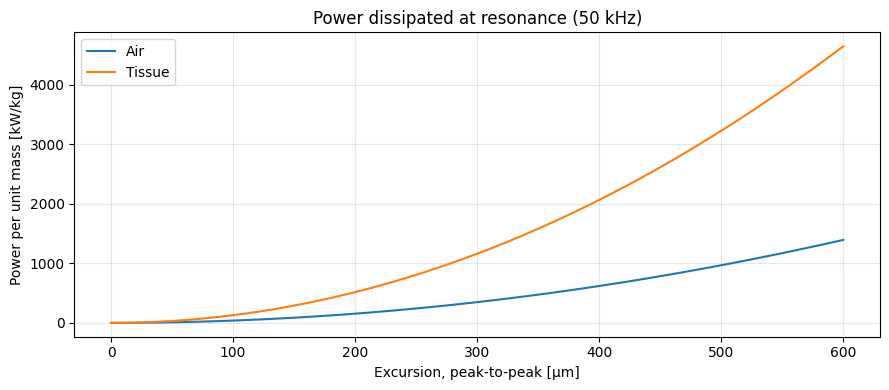

In [20]:
# Power dissipated by damping, per unit mass of the vibrating blade [W/kg]
def power_per_mass(zeta, X):
    return zeta * w**3 * X**2

# Steady-state amplitudes at resonance with the same drive (from point 3)
X_air = a0 / (2 * zeta_air * w**2)
X_tis_fixed_force = a0 / (2 * zeta_tissue * w**2)

P_air = power_per_mass(zeta_air, X_air)
P_tis_force = power_per_mass(zeta_tissue, X_tis_fixed_force)   # same push as air
P_tis_exc = power_per_mass(zeta_tissue, A)                      # same excursion as air

print(f"Air, 150 µm excursion:            P/m = {P_air:.3g} W/kg")
print(f"Tissue, same force (45 µm):       P/m = {P_tis_force:.3g} W/kg ({P_tis_force/P_air:.2f}x air)")
print(f"Tissue, same excursion (150 µm):  P/m = {P_tis_exc:.3g} W/kg ({P_tis_exc/P_air:.2f}x air)")

# Power across the cited excursion range (0-600 µm)
s_range = np.linspace(0, 600e-6, 200)

fig, ax = plt.subplots(figsize=(9, 4))
for label, zeta in [("Air", zeta_air), ("Tissue", zeta_tissue)]:
    ax.plot(s_range * 1e6, power_per_mass(zeta, s_range / 2) / 1e3, label=label)
ax.set_xlabel("Excursion, peak-to-peak [µm]")
ax.set_ylabel("Power per unit mass [kW/kg]")
ax.set_title(f"Power dissipated at resonance ({w/(2*np.pi)/1e3:.0f} kHz)")
ax.legend()
ax.grid(alpha=0.3)
fig.tight_layout()
plt.show()

#### Results

| Case | Excursion | $P/m$ (W/kg) | Relative to air |
|---|---|---|---|
| Air | 150 µm | $8.72 \times 10^4$ | 1.00× |
| Tissue, constant force | 45 µm | $2.62 \times 10^4$ | 0.30× |
| Tissue, constant excursion | 150 µm | $2.91 \times 10^5$ | 3.33× |

- **With a constant force**, contact with tissue *reduces* the dissipated power to 0.3× that in air, because the extra damping causes the excursion to collapse. The scalpel would therefore cut poorly.
- **With a constant excursion**, contact with tissue *increases* the dissipated power by 3.3×, and this additional energy is delivered to the tissue as heat. This is why commercial generators use feedback to maintain a constant excursion under load.
- The plot shows the constant-excursion case across the full 0–600 µm range given in the standard. Power rises with the square of excursion, so doubling the excursion quadruples the power, and tissue dissipates 3.3× more power than air at every excursion.

Power is given per unit mass because the effective vibrating mass of the blade is not known. Multiplying by an estimated mass would give the power in watts; for example, an effective mass of 0.1 g would give approximately 9 W in air and 29 W in tissue at 150 µm. The ratios between cases do not depend on the mass.

*Note: the Q factors used (1000 in air, 300 in tissue) are assumed values, so the absolute figures are illustrative, but the trends and conclusions above do not depend on them.*